Simple Tool-Use AI Agents in LangGraph

Setup Environment Variables

In [2]:
import os
from dotenv import load_dotenv, find_dotenv
load_dotenv()

True

In [3]:
tavily_api_key = os.getenv("TAVILY_API_KEY")
openai_api_key = os.getenv("OPENAI_API_KEY")

State

In [7]:
from typing import Annotated, TypedDict
from langgraph.graph.message import add_messages
class State(TypedDict):
    messages: Annotated[list, add_messages]

Augment the LLM with tools

Here we define our custom search tool and then bind it to the LLM to augment the LLM

In [8]:
from langchain_openai import ChatOpenAI
from langchain_community.utilities.tavily_search import TavilySearchAPIWrapper
from langchain_core.tools import tool
llm = ChatOpenAI(model_name="gpt-4o-mini", temperature=0)

tavily_search = TavilySearchAPIWrapper()
@tool
def search_web(query: str, num_result=5) -> str:
    """Search the web for a query. Useful for general information or general news"""
    result = tavily_search.raw_results(
        query=query,
        max_results=num_result,
        search_depth='advanced'
    )
    return result

tools = [search_web]
llm_with_tools = llm.bind_tools(tools)

/var/folders/y4/j6_cks6j2fb8p7zcm0hyft6r0000gn/T/ipykernel_31244/542249477.py:2: DeprecationWarning: `langchain-community` is being sunset and is no longer actively maintained. See https://github.com/langchain-ai/langchain-community/issues/674 for details and migration guidance toward standalone integration packages.
  from langchain_community.utilities.tavily_search import TavilySearchAPIWrapper


In [9]:
llm_with_tools.invoke('what is the latest news on nvidia')

AIMessage(content='', additional_kwargs={'refusal': None}, response_metadata={'token_usage': {'completion_tokens': 22, 'prompt_tokens': 72, 'total_tokens': 94, 'completion_tokens_details': {'accepted_prediction_tokens': 0, 'audio_tokens': 0, 'reasoning_tokens': 0, 'rejected_prediction_tokens': 0}, 'prompt_tokens_details': {'audio_tokens': 0, 'cached_tokens': 0}}, 'model_provider': 'openai', 'model_name': 'gpt-4o-mini-2024-07-18', 'system_fingerprint': 'fp_54ec6000d4', 'id': 'chatcmpl-EJbVzS38uP4rvFhRVwtUVw6wlTITn', 'service_tier': 'default', 'finish_reason': 'tool_calls', 'logprobs': None}, id='lc_run--01a06170-5142-78d0-9e4d-1923c9180b93-0', tool_calls=[{'name': 'search_web', 'args': {'query': 'latest news on Nvidia', 'num_result': 5}, 'id': 'call_RihzJjtGmpPUTGUOrh6tuQqX', 'type': 'tool_call'}], invalid_tool_calls=[], usage_metadata={'input_tokens': 72, 'output_tokens': 22, 'total_tokens': 94, 'input_token_details': {'audio': 0, 'cache_read': 0}, 'output_token_details': {'audio': 0, 

Create the Graph with the Tool-Use Agentic System

In [10]:
from langgraph.graph import StateGraph, START, END
from langgraph.prebuilt import ToolNode, tools_condition

# Augmented LLM with Tools Node function

In [11]:
def tool_calling_node(state: State) -> State:
    current_state = state.get('messages', [])
    return {'messages': [llm_with_tools.invoke(current_state)]}

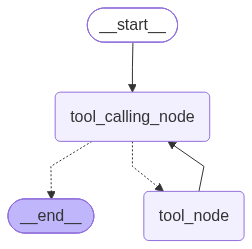

In [15]:
# Build the graph
builder = StateGraph(State)
builder.add_node("tool_calling_node", tool_calling_node)
builder.add_node("tool_node", ToolNode(tools=tools))
# Build the edges
builder.add_edge(START, "tool_calling_node")
builder.add_conditional_edges("tool_calling_node",
                            tools_condition,
                            ["tool_node", END]
                            )
builder.add_edge("tool_node", "tool_calling_node")
builder.add_edge("tool_node", END)
graph = builder.compile()
graph


In [16]:
user_input = "Explain AI in 2 bullets"
for event in agent.stream({"messages": user_input},
                          stream_mode='values'):
    event['messages'][-1].pretty_print()

================================ Human Message =================================

Explain AI in 2 bullets
================================== Ai Message ==================================

- **Definition**: Artificial Intelligence (AI) refers to the simulation of human intelligence in machines that are programmed to think, learn, and perform tasks that typically require human cognitive functions, such as problem-solving, understanding language, and recognizing patterns.

- **Applications**: AI is utilized across various fields, including healthcare (for diagnostics and personalized medicine), finance (for fraud detection and algorithmic trading), autonomous vehicles, customer service (via chatbots), and many more, enhancing efficiency and decision-making processes.


In [17]:
user_input = "What is the latest news on OpenAI product releases"
for event in agent.stream({"messages": user_input},
                          stream_mode='values'):
    event['messages'][-1].pretty_print()

================================ Human Message =================================

What is the latest news on OpenAI product releases
================================== Ai Message ==================================
Tool Calls:
  search_web (call_f5itTRRdG31iq6AGMSoF27sL)
 Call ID: call_f5itTRRdG31iq6AGMSoF27sL
  Args:
    query: OpenAI product releases news
    num_result: 5
================================= Tool Message =================================
Name: search_web

{"query": "OpenAI product releases news", "follow_up_questions": null, "answer": null, "images": [], "results": [{"url": "https://openai.com/news/company-announcements", "title": "OpenAI Newsroom | Recent news", "content": "## Recent news\n\n\"\"\n\nProductJul 9, 2026\n\n\"\"\n\nProductJul 9, 2026\n\nGPT-Daybreak > Cover\n\nSecurityAug 10, 2026\n\nprice-performance-frontier art-card 1x1\n\nProductJul 30, 2026\n\nProductJul 9, 2026\n\n\"\"\n\nProductJul 9, 2026\n\nGPT-Daybreak > Cover\n\nSecurityAug 10, 2026\n\nprice-pe

In [18]:
from IPython.display import display, Markdown

display(Markdown(event['messages'][-1].content))

Here are the latest updates on OpenAI's product releases:

1. **GPT-5.6**: Released on July 9, 2026, this model offers enhanced intelligence, stronger performance per dollar, and increased capabilities for demanding tasks. [More details here](https://openai.com/research/index/release).

2. **GPT-Live**: Introduced on July 8, 2026, this new generation of voice models enhances natural human-AI interaction and powers ChatGPT Voice. 

3. **GPT-5.6 Sol**: A preview of this next-generation model was shared on June 26, 2026, showcasing improved capabilities in coding, science, and cybersecurity, along with an advanced safety stack.

4. **ChatGPT Memory System**: On June 4, 2026, OpenAI introduced a new memory system for ChatGPT, allowing it to better remember user preferences and maintain context across conversations.

5. **ChatGPT for Teachers**: Announced on August 31, 2026, this initiative aims to expand access to AI tools for educators.

6. **ChatGPT for Teens**: Launched on August 18, 2026, this version is tailored for younger users.

7. **ChatGPT Ads**: Expanded across Europe on August 24, 2026, allowing businesses to leverage AI for advertising.

For more detailed information, you can visit the [OpenAI Newsroom](https://openai.com/news/company-announcements) or their [Research Release page](https://openai.com/research/index/release).